# Customers Like You

Individual core tasks: DE1-DE5, ML1-ML6 and J1-J2. Truncated SVD is the main method; PCA is the required comparison. No stretch tasks or slides are included. Brief decisions and justifications are maintained in [decisions.txt](decisions.txt).

Run all cells from a fresh kernel. Customer-level artifacts remain under ignored `data/`; only aggregate outputs appear here. Dataset: Chen, D. (2012), Online Retail II, UCI, https://doi.org/10.24432/C5CG6D, CC BY 4.0.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, time, platform, subprocess, textwrap, importlib.metadata
from datetime import datetime
os.environ.setdefault('MPLCONFIGDIR', str(Path('tmp/matplotlib').resolve()))
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
import numpy as np
import pandas as pd
import scipy.sparse as sp
import sklearn
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits, threadpool_info
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
RAW = ROOT / 'data/raw/online_retail_II.xlsx'
DATA, REPORTS, FIGURES, TMP = [ROOT / p for p in ('data/processed', 'reports', 'figures', 'tmp')]
for folder in (DATA, REPORTS, FIGURES, TMP, TMP/'pdfs'):
    folder.mkdir(parents=True, exist_ok=True)
assert RAW.exists(), 'Download Online Retail II and put the workbook in data/raw/.'
assert 'Main method: Truncated SVD' in (ROOT/'decisions.txt').read_text()
SEED, MIN_CUSTOMERS, RANKS = 42, 10, [10, 20, 50, 100, 200]
np.random.seed(SEED)
thread_controller = threadpool_limits(limits=1)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.dpi':140, 'savefig.dpi':200})

def write_json(path, value):
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + '\n')

def record_decision(number, statement):
    path = ROOT/'decisions.txt'
    prefix = f'{number:02d}. '
    lines = path.read_text().splitlines()
    matches = [i for i, line in enumerate(lines) if line.startswith(prefix)]
    if matches:
        lines[matches[0]] = prefix + statement
    else:
        lines.append(prefix + statement)
    path.write_text('\n'.join(lines) + '\n')

def markdown_table(frame):
    return '| ' + ' | '.join(map(str, frame.columns)) + ' |\n' + '| ' + ' | '.join(['---']*len(frame.columns)) + ' |\n' + '\n'.join('| ' + ' | '.join(str(x).replace('|','/') for x in row) + ' |' for row in frame.itertuples(index=False, name=None))

def show_figure(fig, filename):
    fig.savefig(FIGURES/filename, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    display(Image(filename=str(FIGURES/filename)))

pipeline_start = time.perf_counter()
environment = {'python':platform.python_version(), 'platform':platform.platform(),
               'machine':platform.machine(), 'logical_cpus':os.cpu_count(), 'numerical_threads':1,
               'seed':SEED, 'raw_sha256':hashlib.file_digest(RAW.open('rb'), 'sha256').hexdigest(),
               'packages':{p:importlib.metadata.version(p) for p in
                           ['numpy','pandas','openpyxl','scipy','scikit-learn','matplotlib','nbformat','nbconvert','ipykernel','psutil','threadpoolctl','reportlab','pypdf']}}
print('Python', environment['python'], '|', environment['machine'], '| fixed seed', SEED, '| numerical threads: 1')

Python 3.12.14 | arm64 | fixed seed 42 | numerical threads: 1


## DE1: source profile

Both sheets are loaded from the raw workbook on every execution. The tables show schema, row counts and missingness without exposing customer records.

In [2]:
load_start = time.perf_counter()
sheets = pd.read_excel(RAW, sheet_name=None, dtype={'Invoice':'string', 'StockCode':'string'})
profile_rows, sheet_rows, frames = [], [], []
for sheet_name, frame in sheets.items():
    frame.columns = frame.columns.str.strip()
    sheet_rows.append({'sheet':sheet_name, 'rows':len(frame), 'columns':len(frame.columns),
                       'date_min':str(frame.InvoiceDate.min()), 'date_max':str(frame.InvoiceDate.max())})
    for col in frame:
        profile_rows.append({'sheet':sheet_name, 'column':col, 'dtype':str(frame[col].dtype),
                             'rows':len(frame), 'missing':int(frame[col].isna().sum()),
                             'missing_percent':float(frame[col].isna().mean()*100)})
    frames.append(frame)
raw = pd.concat(frames, ignore_index=True)
assert len(sheets)==2 and len(raw)==sum(r['rows'] for r in sheet_rows)
for col in raw:
    profile_rows.append({'sheet':'Combined', 'column':col, 'dtype':str(raw[col].dtype),
                         'rows':len(raw), 'missing':int(raw[col].isna().sum()),
                         'missing_percent':float(raw[col].isna().mean()*100)})
data_profile = pd.DataFrame(profile_rows)
sheet_profile = pd.DataFrame(sheet_rows)
data_profile.to_csv(REPORTS/'data_profile.csv', index=False)
sheet_profile.to_csv(REPORTS/'sheet_profile.csv', index=False)
raw_duplicates = int(raw.duplicated().sum())
raw_stats = {'rows':len(raw), 'sheets':sheet_rows, 'date_min':str(raw.InvoiceDate.min()),
             'date_max':str(raw.InvoiceDate.max()), 'unique_customers':int(raw['Customer ID'].nunique()),
             'unique_products':int(raw.StockCode.nunique()), 'exact_repeated_lines':raw_duplicates,
             'load_seconds':time.perf_counter()-load_start}
write_json(REPORTS/'source_summary.json', raw_stats)
display(sheet_profile)
display(data_profile[data_profile.sheet.eq('Combined')].drop(columns='sheet'))
print(f"Raw total: {len(raw):,}; exact repeated lines retained: {raw_duplicates:,}.")
del sheets, frames, frame

,sheet,rows,columns,date_min,date_max
0,Year 2009-2010,525461,8,2009-12-01 07:45:00,2010-12-09 20:01:00
1,Year 2010-2011,541910,8,2010-12-01 08:26:00,2011-12-09 12:50:00


,column,dtype,rows,missing,missing_percent
16,Invoice,string,1067371,0,0.000000
17,StockCode,string,1067371,0,0.000000
18,Description,object,1067371,4382,0.410541
19,Quantity,int64,1067371,0,0.000000
20,InvoiceDate,datetime64[ns],1067371,0,0.000000
21,Price,float64,1067371,0,0.000000
22,Customer ID,float64,1067371,243007,22.766873
23,Country,object,1067371,0,0.000000


Raw total: 1,067,371; exact repeated lines retained: 34,335.


## DE2: deterministic cleaning

The removal log is sequential: a line matching multiple rules is counted at the first rule that removes it. See decisions 04, 08 and 10 for purchase values, privacy and repeated-line handling.

In [3]:
clean = raw.copy()
clean['Invoice'] = clean.Invoice.astype('string').str.strip().str.upper()
clean['StockCode'] = clean.StockCode.astype('string').str.strip().str.upper()
clean['InvoiceDate'] = pd.to_datetime(clean.InvoiceDate, errors='coerce')
clean['Quantity'] = pd.to_numeric(clean.Quantity, errors='coerce')
clean['Price'] = pd.to_numeric(clean.Price, errors='coerce')
clean['Customer ID'] = pd.to_numeric(clean['Customer ID'], errors='coerce')
clean['Description'] = clean.Description.astype('string').str.strip().str.upper()
clean['Country'] = clean.Country.astype('string').str.strip()
NON_PRODUCTS = {'POST','DOT','M','D','BANK CHARGES','AMAZONFEE','ADJUST','ADJUST2',
                'B','C2','C3','CRUK','S','GIFT','TEST001','TEST002'}
cleaning_rows = []
def remove_rows(name, mask):
    global clean
    before = len(clean)
    clean = clean.loc[~mask.fillna(False)].copy()
    cleaning_rows.append({'rule':name, 'rows_before':before,
                          'rows_removed':before-len(clean), 'rows_after':len(clean)})

remove_rows('Cancellation invoice (C prefix)', clean.Invoice.str.startswith('C'))
remove_rows('Non-positive or invalid quantity', ~np.isfinite(clean.Quantity) | clean.Quantity.le(0))
remove_rows('Non-positive or invalid price', ~np.isfinite(clean.Price) | clean.Price.le(0))
remove_rows('Non-product, voucher, sample or test code',
            clean.StockCode.isin(NON_PRODUCTS) | clean.StockCode.str.startswith('GIFT_'))
remove_rows('Missing or invalid customer ID', clean['Customer ID'].isna() |
            ~np.isfinite(clean['Customer ID']) | clean['Customer ID'].le(0) |
            clean['Customer ID'].mod(1).ne(0))
remove_rows('Missing date, invoice or stock code', clean.InvoiceDate.isna() |
            clean.Invoice.isna() | clean.Invoice.eq('') | clean.StockCode.isna() | clean.StockCode.eq(''))
clean['Customer ID'] = clean['Customer ID'].astype('int64').astype('string')
cleaning_log = pd.DataFrame(cleaning_rows)
assert cleaning_log.rows_removed.sum()+len(clean)==len(raw)
assert (clean.Quantity.gt(0)&clean.Price.gt(0)).all()
assert not clean.Invoice.str.startswith('C').any()
assert not clean.StockCode.isin(NON_PRODUCTS).any()
assert clean[['Invoice','StockCode','InvoiceDate','Customer ID']].notna().all().all()
cleaning_log.to_csv(REPORTS/'cleaning_log.csv', index=False)
clean_stats = {'rows':len(clean), 'rows_removed':len(raw)-len(clean),
               'exact_repeated_clean_lines_retained':int(clean.duplicated().sum()),
               'missing_description_retained':int(clean.Description.isna().sum()),
               'unique_customers':int(clean['Customer ID'].nunique()),
               'unique_products':int(clean.StockCode.nunique()), 'excluded_codes':sorted(NON_PRODUCTS),
               'excluded_prefixes':['GIFT_']}
write_json(REPORTS/'cleaning_summary.json', clean_stats)
display(cleaning_log)
print(f"Clean positive purchase lines: {len(clean):,}.")
del raw

,rule,rows_before,rows_removed,rows_after
0,Cancellation invoice (C prefix),1067371,19494,1047877
1,Non-positive or invalid quantity,1047877,3457,1044420
2,Non-positive or invalid price,1044420,2750,1041670
3,"Non-product, voucher, sample or test code",1041670,4649,1037021
4,Missing or invalid customer ID,1037021,234370,802651
5,"Missing date, invoice or stock code",802651,0,802651


Clean positive purchase lines: 802,651.


## DE3-DE5: temporal hold-out and sparse matrix

The test period is isolated before product filtering, factor fitting or popularity estimation. Targets are distinct new-to-customer purchases. The primary cohort contains known customers and products with a usable training history; coverage and exclusions are reported separately.

In [4]:
test_end = clean.InvoiceDate.max().normalize()+pd.Timedelta(days=1)
test_start = test_end-pd.DateOffset(months=2)
train = clean.loc[clean.InvoiceDate.lt(test_start)].copy()
test_period = clean.loc[clean.InvoiceDate.ge(test_start)&clean.InvoiceDate.lt(test_end)].copy()
pair_cols = ['Customer ID','StockCode']
train_pairs = train[pair_cols].drop_duplicates()
test_pairs = test_period[pair_cols].drop_duplicates()
train_pair_index = pd.MultiIndex.from_frame(train_pairs)
novel_mask = ~pd.MultiIndex.from_frame(test_pairs).isin(train_pair_index)
novel = test_pairs.loc[novel_mask].copy()
assert train.InvoiceDate.max()<test_start<=test_period.InvoiceDate.min()
assert not pd.MultiIndex.from_frame(novel).isin(train_pair_index).any()

support = train_pairs.groupby('StockCode')['Customer ID'].nunique()
products = np.array(sorted(support.index[support.ge(MIN_CUSTOMERS)]), dtype=str)
matrix_train = train.loc[train.StockCode.isin(products)]
customers = np.array(sorted(matrix_train['Customer ID'].unique()), dtype=str)
customer_index = pd.Index(customers)
product_index = pd.Index(products)
aggregated = matrix_train.groupby(pair_cols, sort=True).Quantity.sum().reset_index()
row_index = customer_index.get_indexer(aggregated['Customer ID'])
col_index = product_index.get_indexer(aggregated.StockCode)
A = sp.csr_matrix((np.log1p(aggregated.Quantity.to_numpy(dtype=float)),(row_index,col_index)),
                  shape=(len(customers),len(products)), dtype=np.float64)
A.sort_indices()
assert (row_index>=0).all() and (col_index>=0).all() and A.nnz==len(aggregated)
assert np.all(A.data>0) and np.isfinite(A.data).all()
assert np.all(np.diff(A.indptr)>0)
assert A.shape[1]>max(RANKS) and A.shape[0]>max(RANKS)
sp.save_npz(DATA/'customer_product.npz', A)
pd.DataFrame({'row_index':np.arange(len(customers)), 'customer_id':customers}).to_csv(DATA/'customer_index.csv', index=False)

description_counts = train.dropna(subset=['Description']).groupby(['StockCode','Description']).size().rename('lines').reset_index()
descriptions = description_counts.sort_values(['StockCode','lines','Description'],ascending=[True,False,True]).drop_duplicates('StockCode').set_index('StockCode').Description
product_names = np.array([descriptions.get(p,p) for p in products], dtype=str)
product_map = pd.DataFrame({'column_index':np.arange(len(products)), 'stock_code':products,
                           'description':product_names, 'training_customers':support.reindex(products).to_numpy()})
product_map.to_csv(DATA/'product_index.csv', index=False)
train.to_csv(DATA/'train.csv.gz', index=False)
test_period.to_csv(DATA/'test_period.csv.gz', index=False)
novel.to_csv(DATA/'test_new_pairs.csv.gz', index=False)

novel['row_index'] = customer_index.get_indexer(novel['Customer ID'])
novel['column_index'] = product_index.get_indexer(novel.StockCode)
known = novel.row_index.ge(0)
catalogued = novel.column_index.ge(0)
eligible_pairs = novel.loc[known&catalogued, ['row_index','column_index']].astype(int)
test_targets = {int(r):set(g.column_index) for r,g in eligible_pairs.groupby('row_index')}
test_customer_rows = np.array(sorted(test_targets), dtype=int)
assert len(test_targets)>0
assert all(A[r,list(targets)].nnz==0 for r,targets in test_targets.items())
np.savez(DATA/'test_targets.npz', customer_rows=eligible_pairs.row_index.to_numpy(), product_columns=eligible_pairs.column_index.to_numpy())

split_summary = {'test_start_inclusive':str(test_start), 'test_end_exclusive':str(test_end),
    'training_lines':len(train), 'test_period_lines':len(test_period),
    'test_customers_total':int(test_period['Customer ID'].nunique()),
    'test_customer_product_pairs':len(test_pairs), 'new_customer_product_pairs':len(novel),
    'repeat_pairs_excluded':int((~novel_mask).sum()),
    'novel_pairs_unknown_customer':int((~known).sum()),
    'novel_pairs_known_customer_unavailable_product':int((known&~catalogued).sum()),
    'evaluable_novel_pairs':len(eligible_pairs), 'evaluable_customers':len(test_targets),
    'novel_customers_total':int(novel['Customer ID'].nunique()),
    'novel_pair_coverage_percent':100*len(eligible_pairs)/len(novel),
    'novel_customer_coverage_percent':100*len(test_targets)/novel['Customer ID'].nunique(),
    'training_products_before_filter':int(train.StockCode.nunique()),
    'training_customers_before_filter':int(train['Customer ID'].nunique()),
    'training_customers_lost_to_filter':int(train['Customer ID'].nunique()-len(customers)),
    'minimum_training_customer_support':MIN_CUSTOMERS}
assert split_summary['novel_pairs_unknown_customer']+split_summary['novel_pairs_known_customer_unavailable_product']+len(eligible_pairs)==len(novel)
write_json(REPORTS/'split_summary.json', split_summary)
csr_bytes = A.data.nbytes+A.indices.nbytes+A.indptr.nbytes
dense_bytes = A.shape[0]*A.shape[1]*A.dtype.itemsize
matrix_summary = {'customers':A.shape[0], 'products':A.shape[1], 'nonzeros':A.nnz,
    'sparsity_percent':100*(1-A.nnz/np.prod(A.shape)), 'dtype':str(A.dtype),
    'dense_bytes':dense_bytes, 'csr_bytes':csr_bytes,
    'npz_disk_bytes':(DATA/'customer_product.npz').stat().st_size}
matrix_summary = {k:int(v) if isinstance(v,np.integer) else float(v) if isinstance(v,np.floating) else v for k,v in matrix_summary.items()}
write_json(REPORTS/'matrix_summary.json', matrix_summary)
matrix_report = f"""# Training matrix report

Purchase value: log(1 + total training units) per customer-product pair.

Shape: {A.shape[0]:,} customers x {A.shape[1]:,} products. Nonzeros: {A.nnz:,}. Sparsity: {matrix_summary['sparsity_percent']:.2f}%.

Float64 dense equivalent: {dense_bytes/1e6:.3f} MB. CSR arrays: {csr_bytes/1e6:.3f} MB. Compressed NPZ on disk: {matrix_summary['npz_disk_bytes']/1e6:.3f} MB. MB means 1,000,000 bytes throughout.

Training ends before {test_start:%Y-%m-%d}; test is [{test_start:%Y-%m-%d}, {test_end:%Y-%m-%d}). Catalogue threshold: {MIN_CUSTOMERS} distinct training customers.

Evaluable cohort: {len(test_targets):,} customers and {len(eligible_pairs):,} new purchase pairs. This covers {split_summary['novel_pair_coverage_percent']:.2f}% of all new test pairs and {split_summary['novel_customer_coverage_percent']:.2f}% of customers with new test purchases. See split_summary.json for all exclusions.

No held-out pair appears in its customer's full pre-filter training history. Matrix, catalogue, descriptions and profiles use training only. Customer maps and train/test records are stored locally under ignored data/.
"""
(REPORTS/'matrix_report.md').write_text(matrix_report)
display(pd.DataFrame([matrix_summary]))
display(pd.DataFrame({'measure':list(split_summary), 'value':list(split_summary.values())}))
record_decision(15, f'Test window: [{test_start:%Y-%m-%d}, {test_end:%Y-%m-%d}); evaluate known customers with retained novel products, and report coverage so cold-start exclusions are visible.')

,customers,products,nonzeros,sparsity_percent,dtype,dense_bytes,csr_bytes,npz_disk_bytes
0,5482,3690,414566,97.950593,float64,161828640,4996724,1056682


,measure,value
0,test_start_inclusive,2011-10-10 00:00:00
1,test_end_exclusive,2011-12-10 00:00:00
2,training_lines,684930
3,test_period_lines,117721
4,test_customers_total,2408
5,test_customer_product_pairs,94306
6,new_customer_product_pairs,62625
7,repeat_pairs_excluded,31681
8,novel_pairs_unknown_customer,13279
9,novel_pairs_known_customer_unavailable_product,4602


## ML1-ML2: isolated fits and reconstruction curve

ML1 was recorded in decisions.txt before any fit. Each fit below runs in a fresh process with the same matrix and one numerical thread. The worker is embedded here and generated only in ignored tmp/; it is a measurement helper, not the excluded DE6 rebuild script.

SVD error is `||A - (A V_k) V_k^T||_F / ||A||_F`. Orthogonality allows it to be computed from sparse A and the small projected scores. PCA additionally reports explained variance and original-scale error; its reconstruction restores column means. No dense full-matrix reconstruction is allocated.

SVD k=10: error=0.8761; fit=0.091s


SVD k=20: error=0.8459; fit=0.118s


SVD k=50: error=0.7895; fit=0.293s


SVD k=100: error=0.7274; fit=0.257s


SVD k=200: error=0.6388; fit=0.573s


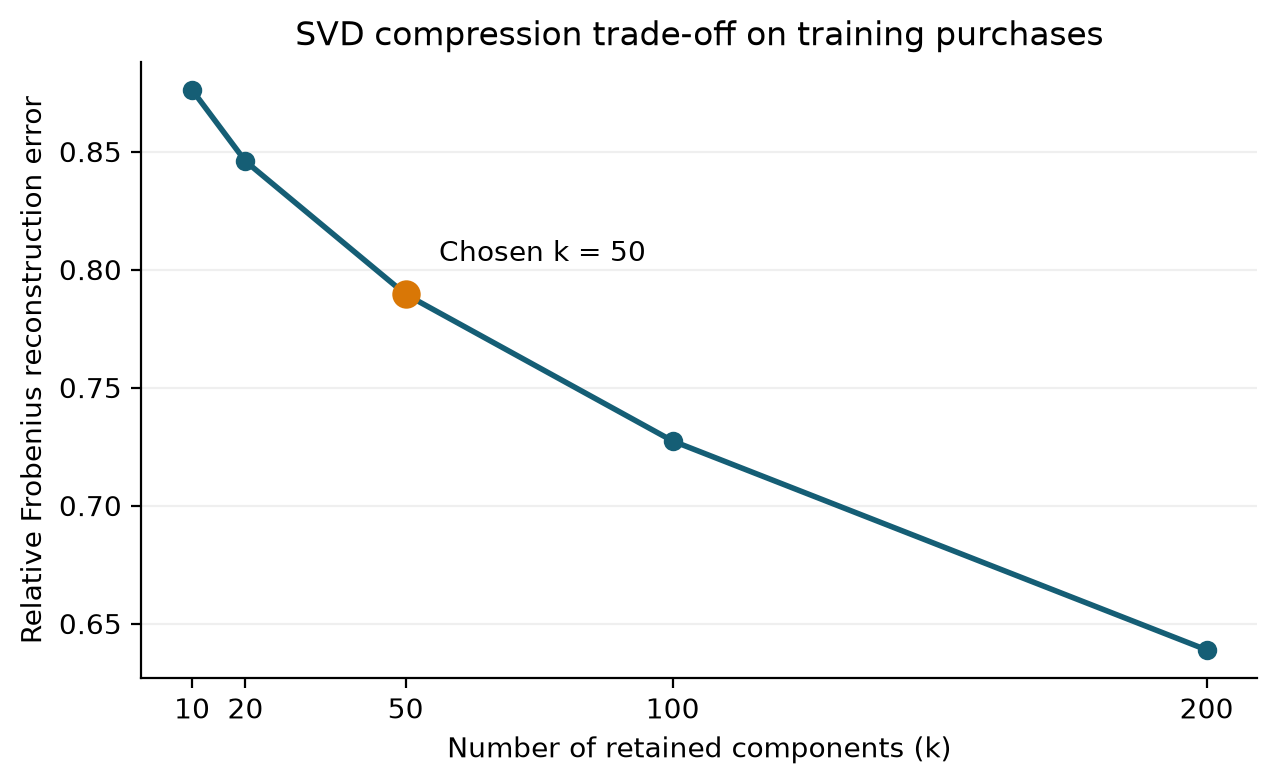

,k,relative_reconstruction_error,fit_seconds,peak_fit_rss_mb,factor_mb,dense_reduction_percent,elbow_gap,selected
0,10,0.8761,0.0910,155.4022,0.7338,99.5465,0.0000,False
1,20,0.8459,0.1180,144.7690,1.4677,99.0931,0.0748,False
2,50,0.7895,0.2926,150.3068,3.6692,97.7327,0.1546,True
3,100,0.7274,0.2569,181.6330,7.3384,95.4653,0.1533,False
4,200,0.6388,0.5728,206.1599,14.6768,90.9307,0.0000,False


In [5]:
worker_source = r'''
import sys, json, time, threading, os
from pathlib import Path
import numpy as np
import scipy.sparse as sp
import psutil
from sklearn.decomposition import PCA, TruncatedSVD
from threadpoolctl import threadpool_limits
method, rank, matrix_path, prefix = sys.argv[1], int(sys.argv[2]), sys.argv[3], Path(sys.argv[4])
A = sp.load_npz(matrix_path)
model = (TruncatedSVD(n_components=rank, algorithm='randomized', n_iter=7, n_oversamples=10, random_state=42)
         if method=='SVD' else PCA(n_components=rank, svd_solver='arpack', random_state=42, tol=0.0))
process = psutil.Process()
baseline = process.memory_info().rss
peak = [baseline]
stop = threading.Event()
def sample():
    while not stop.is_set():
        peak[0] = max(peak[0], process.memory_info().rss)
        stop.wait(0.002)
monitor = threading.Thread(target=sample, daemon=True)
with threadpool_limits(limits=1):
    monitor.start()
    start = time.perf_counter()
    model.fit(A)
    fit_seconds = time.perf_counter()-start
    peak[0] = max(peak[0], process.memory_info().rss)
    stop.set(); monitor.join()
    start = time.perf_counter()
    scores = model.transform(A)
    transform_seconds = time.perf_counter()-start
Vt = model.components_
assert np.linalg.norm(Vt@Vt.T-np.eye(rank))<1e-8
norm2 = float(A.multiply(A).sum())
mean = model.mean_ if method=='PCA' else np.zeros(0)
centred_norm2 = norm2-A.shape[0]*float(mean@mean) if method=='PCA' else norm2
residual2 = max(0., centred_norm2-float(np.sum(scores*scores)))
original_error = float(np.sqrt(residual2/norm2))
block = A[:8].toarray()
reconstructed = scores[:8]@Vt
if method=='PCA': reconstructed += mean
direct2 = float(np.sum((block-reconstructed)**2))
small_centred = block-mean if method=='PCA' else block
identity2 = float(np.sum(small_centred**2)-np.sum(scores[:8]**2))
assert np.isclose(direct2, identity2, atol=1e-7, rtol=1e-8)
np.savez(prefix.with_suffix('.npz'), components=Vt, scores=scores, singular_values=model.singular_values_, mean=mean)
stats = {'method':method,'k':rank,'fit_seconds':fit_seconds,'transform_seconds':transform_seconds,
         'peak_fit_rss_mb':peak[0]/1e6,'baseline_rss_mb':baseline/1e6,
         'peak_increment_mb':(peak[0]-baseline)/1e6,
         'factor_bytes':int(Vt.nbytes+scores.nbytes+mean.nbytes+model.singular_values_.nbytes),
         'relative_reconstruction_error':original_error,
         'relative_centred_error':float(np.sqrt(residual2/centred_norm2)),
         'explained_variance_ratio':float(model.explained_variance_ratio_.sum()),
         'orthogonality_checked':True, 'small_dense_error_check':True,
         'sampling_interval_seconds':0.002}
prefix.with_suffix('.json').write_text(json.dumps(stats,indent=2)+'\n')
print(json.dumps(stats))
'''
worker_path = TMP/'fit_worker.py'
worker_path.write_text(textwrap.dedent(worker_source))
def isolated_fit(method, k):
    prefix = DATA/f'{method.lower()}_k{k}'
    env = os.environ.copy()
    env.update({'OPENBLAS_NUM_THREADS':'1','OMP_NUM_THREADS':'1','MKL_NUM_THREADS':'1','VECLIB_MAXIMUM_THREADS':'1'})
    result = subprocess.run([sys.executable,str(worker_path),method,str(k),str(DATA/'customer_product.npz'),str(prefix)],
                            check=True, capture_output=True, text=True, env=env)
    stats = json.loads(prefix.with_suffix('.json').read_text())
    if result.stderr.strip():
        print(result.stderr.strip())
    return stats

rank_stats = []
for k in RANKS:
    stats = isolated_fit('SVD', k)
    rank_stats.append(stats)
    print(f"SVD k={k}: error={stats['relative_reconstruction_error']:.4f}; fit={stats['fit_seconds']:.3f}s")
rank_results = pd.DataFrame(rank_stats)
rank_results['factor_mb'] = rank_results.factor_bytes/1e6
rank_results['dense_reduction_percent'] = 100*(1-rank_results.factor_bytes/dense_bytes)
x = (rank_results.k-rank_results.k.min())/(rank_results.k.max()-rank_results.k.min())
errors = rank_results.relative_reconstruction_error
y = (errors-errors.min())/(errors.max()-errors.min())
rank_results['elbow_gap'] = (1-x)-y
rank_results['within_targets'] = rank_results.dense_reduction_percent.ge(90)&rank_results.fit_seconds.lt(60)
feasible = rank_results.loc[rank_results.within_targets]
assert len(feasible), 'No required rank fits the declared memory/time targets; report the failure before proceeding.'
chosen = feasible.sort_values(['elbow_gap','k'], ascending=[False,True]).iloc[0]
CHOSEN_K = int(chosen.k)
rank_results['selected'] = rank_results.k.eq(CHOSEN_K)
rank_results.to_csv(REPORTS/'svd_rank_results.csv', index=False)
record_decision(16, f'Chosen k={CHOSEN_K}: maximum feasible training-curve elbow gap ({chosen.elbow_gap:.3f}); this was selected before final test hit rates. Keep the rank fixed for PCA.')
write_json(DATA/'frozen_model_choice.json', {'k':CHOSEN_K,'value':'log1p(total_quantity)',
          'minimum_customers':MIN_CUSTOMERS, 'scoring':'weighted cosine over normalised V rows',
          'test_results_read_for_choice':False})
fig, ax = plt.subplots(figsize=(7.2,4))
ax.plot(RANKS, errors, marker='o', color='#155E75', linewidth=2)
ax.scatter([CHOSEN_K], [chosen.relative_reconstruction_error], s=85, color='#D97706', zorder=3)
ax.annotate(f'Chosen k = {CHOSEN_K}', (CHOSEN_K,chosen.relative_reconstruction_error), xytext=(12,12),textcoords='offset points')
ax.set(xlabel='Number of retained components (k)', ylabel='Relative Frobenius reconstruction error', title='SVD compression trade-off on training purchases')
ax.set_xticks(RANKS); ax.grid(axis='y', alpha=.2)
show_figure(fig,'svd_reconstruction_error.png')
display(rank_results[['k','relative_reconstruction_error','fit_seconds','peak_fit_rss_mb','factor_mb','dense_reduction_percent','elbow_gap','selected']].round(4))

## ML3: product and customer recommendation functions

Product vectors are normalised rows of V. Customer scores are weighted sums of product cosine similarities using the training purchase values in A. Previously bought products are excluded. A stable product-code order resolves equal scores. Zero profiles use the same unseen best-seller fallback; the count is reported.

In [6]:
svd_stats = rank_stats[RANKS.index(CHOSEN_K)]
with np.load(DATA/f'svd_k{CHOSEN_K}.npz') as factors:
    svd_components, svd_scores = factors['components'].copy(), factors['scores'].copy()
    svd_singular_values = factors['singular_values'].copy()
P_svd = normalize(svd_components.T)
popularity = train.groupby('StockCode').Quantity.sum().reindex(products).to_numpy(dtype=float)
best_seller_order = np.argsort(-popularity, kind='stable')

def best_sellers_for_customer(customer_row, n=10):
    seen = A.indices[A.indptr[customer_row]:A.indptr[customer_row+1]]
    return best_seller_order[~np.isin(best_seller_order,seen)][:n]

def similar_products(stock_code, n=10, product_vectors=None):
    vectors = P_svd if product_vectors is None else product_vectors
    j = product_index.get_indexer([str(stock_code).strip().upper()])[0]
    if j<0:
        raise KeyError('Product is outside the retained training catalogue.')
    if np.linalg.norm(vectors[j])<=1e-12:
        raise ValueError('Product has a zero factor vector; use the best-seller fallback.')
    scores = vectors@vectors[j]
    scores[j] = -np.inf
    scores[np.linalg.norm(vectors,axis=1)<=1e-12] = -np.inf
    indices = np.argsort(-scores,kind='stable')[:n]
    return pd.DataFrame({'stock_code':products[indices], 'description':product_names[indices],
                         'cosine_similarity':scores[indices]})

def recommend_customer(customer_row, n=10, product_vectors=None):
    vectors = P_svd if product_vectors is None else product_vectors
    if not 0<=int(customer_row)<A.shape[0]:
        raise IndexError('Use a valid anonymised matrix row.')
    profile = np.asarray(A[int(customer_row)]@vectors).ravel()
    if np.linalg.norm(profile)<=1e-12:
        chosen_indices = best_sellers_for_customer(int(customer_row),n)
        values = np.zeros(len(chosen_indices))
    else:
        scores = profile@vectors.T
        seen = A.indices[A.indptr[customer_row]:A.indptr[customer_row+1]]
        scores[seen] = -np.inf
        chosen_indices = np.argsort(-scores,kind='stable')[:n]
        values = scores[chosen_indices]
    return pd.DataFrame({'stock_code':products[chosen_indices], 'description':product_names[chosen_indices],
                         'weighted_similarity_score':values})

def catalogue_neighbours(vectors, n=10, batch_size=128):
    neighbours = np.empty((len(products),n), dtype=np.int32)
    cosine = np.empty((len(products),n), dtype=float)
    norms = np.linalg.norm(vectors,axis=1)
    zero_fallbacks = 0
    for start in range(0,len(products),batch_size):
        stop = min(start+batch_size,len(products))
        scores = vectors[start:stop]@vectors.T
        scores[np.arange(stop-start),np.arange(start,stop)] = -np.inf
        scores[:,norms<=1e-12] = -np.inf
        for local,j in enumerate(range(start,stop)):
            if norms[j]<=1e-12:
                indices = best_seller_order[best_seller_order!=j][:n]
                zero_fallbacks += 1
            else:
                indices = np.argsort(-scores[local],kind='stable')[:n]
            neighbours[j], cosine[j] = indices,scores[local,indices]
    assert np.all(neighbours!=np.arange(len(products))[:,None])
    return neighbours,cosine,zero_fallbacks

def all_customer_recommendations(vectors, n=10, batch_size=128):
    profiles = A@vectors
    recommendations = np.empty((A.shape[0],n),dtype=np.int32)
    zero_fallbacks = 0
    for start in range(0,A.shape[0],batch_size):
        stop = min(start+batch_size,A.shape[0])
        scores = profiles[start:stop]@vectors.T
        for local,r in enumerate(range(start,stop)):
            seen = A.indices[A.indptr[r]:A.indptr[r+1]]
            scores[local,seen] = -np.inf
            if np.linalg.norm(profiles[r])<=1e-12:
                recommendations[r] = best_sellers_for_customer(r,n)
                zero_fallbacks += 1
            else:
                recommendations[r] = np.argsort(-scores[local],kind='stable')[:n]
            assert len(set(recommendations[r]))==n
            assert not np.intersect1d(seen,recommendations[r]).size
    return recommendations,zero_fallbacks

def hits_at_10(recommendations):
    return np.array([bool(set(recommendations[r])&test_targets[r]) for r in test_customer_rows],dtype=bool)

example_product = str(products[best_seller_order[0]])
print('Example product:', example_product, product_names[best_seller_order[0]])
display(similar_products(example_product).round(4))
display(recommend_customer(0).head(5).round(4))

Example product: 84077 WORLD WAR 2 GLIDERS ASSTD DESIGNS


,stock_code,description,cosine_similarity
0,35015,JACOBS LADDER SMALL,0.5161
1,85227,SET OF 6 3D KIT CARDS FOR KIDS,0.4317
2,35096B,RED VICTORIAN FABRIC HEART BOX,0.4123
3,20864,DENIM PATCH PENCIL CASE BUTTERFLY,0.4019
4,22440,BALLOON WATER BOMB PACK OF 35,0.4016
5,77079,DOLPHIN WINDMILL,0.4001
6,84007,MAGIC GARDEN MOUNT FUJI,0.3599
7,21878,PACK OF 6 SANDCASTLE FLAGS ASSORTED,0.3397
8,21833,CAMOUFLAGE LED TORCH,0.3374
9,90112,PINK DOLLY HAIR CLIPS,0.3352


,stock_code,description,weighted_similarity_score
0,48129,DOORMAT TOPIARY,12.0173
1,48116,DOOR MAT MULTICOLOUR STRIPE,11.2176
2,23167,SMALL CERAMIC TOP STORAGE JAR,10.9536
3,23165,LARGE CERAMIC TOP STORAGE JAR,10.7233
4,84031B,CHARLIE LOLA BLUE HOT WATER BOTTLE,10.7126


## ML4-ML5: held-out evaluation and required PCA comparison

The model configuration is now frozen. The baseline and both models use the same retained catalogue, test customers and unseen-product exclusion. Hit rate counts each eligible customer once if at least one held-out product appears in the top 10. The temporal test assesses new-product discovery for returning customers, not repeat purchases or cold starts.

In [7]:
pca_stats = isolated_fit('PCA', CHOSEN_K)
with np.load(DATA/f'pca_k{CHOSEN_K}.npz') as factors:
    pca_components, pca_scores = factors['components'].copy(), factors['scores'].copy()
P_pca = normalize(pca_components.T)
baseline_recommendations = np.stack([best_sellers_for_customer(r) for r in range(A.shape[0])])
baseline_hits = hits_at_10(baseline_recommendations)
baseline_rate = float(baseline_hits.mean())
evaluation_rows, model_recommendations, model_hits, timing_rows = [], {}, {}, []
for method,vectors,stats in [('SVD',P_svd,svd_stats),('PCA',P_pca,pca_stats)]:
    start = time.perf_counter()
    neighbours,cosines,product_fallbacks = catalogue_neighbours(vectors)
    catalogue_seconds = time.perf_counter()-start
    start = time.perf_counter()
    recs,customer_fallbacks = all_customer_recommendations(vectors)
    customer_seconds = time.perf_counter()-start
    hits = hits_at_10(recs)
    np.savez(DATA/f'{method.lower()}_recommendations.npz', product_neighbours=neighbours,
             product_cosines=cosines, customer_recommendations=recs)
    model_recommendations[method],model_hits[method] = recs,hits
    timing_rows.append({'method':method,'fit_seconds':stats['fit_seconds'],
        'factor_transform_seconds':stats['transform_seconds'],'catalogue_refresh_seconds':catalogue_seconds,
        'all_customer_scoring_seconds':customer_seconds,
        'fit_plus_catalogue_seconds':stats['fit_seconds']+catalogue_seconds,
        'model_refresh_total_seconds':stats['fit_seconds']+stats['transform_seconds']+catalogue_seconds+customer_seconds,
        'product_zero_vector_fallbacks':product_fallbacks,'customer_zero_profile_fallbacks':customer_fallbacks})
    evaluation_rows.append({'method':method,'k':CHOSEN_K,'hit_customers':int(hits.sum()),
        'eligible_customers':len(hits),'hit_rate_at_10':float(hits.mean()),
        'baseline_hit_customers':int(baseline_hits.sum()),'baseline_hit_rate_at_10':baseline_rate,
        'difference_percentage_points':100*(hits.mean()-baseline_rate)})

evaluation = pd.DataFrame(evaluation_rows)
timings = pd.DataFrame(timing_rows)
evaluation.to_csv(REPORTS/'evaluation.csv',index=False)
timings.to_csv(REPORTS/'timings.csv',index=False)
display(evaluation.round(4)); display(timings.round(4))

# Paired bootstrap is descriptive uncertainty for the fixed final cohort; it is not used for tuning.
rng = np.random.default_rng(SEED)
bootstrap_diffs = np.empty(2000)
paired_difference = model_hits['SVD'].astype(float)-baseline_hits.astype(float)
for b in range(len(bootstrap_diffs)):
    bootstrap_diffs[b] = 100*rng.choice(paired_difference,size=len(paired_difference),replace=True).mean()
ci = np.quantile(bootstrap_diffs,[.025,.975])
write_json(REPORTS/'paired_uncertainty.json', {'svd_minus_baseline_pp':100*paired_difference.mean(),
    'bootstrap_95_percent_interval_pp':ci.tolist(), 'resamples':2000,'seed':SEED,
    'unit':'eligible customer','conditional_on_fixed_cohort':True})

volumes = np.asarray(A.sum(axis=1)).ravel()
component_rows = []
component_descriptions = {}
for method,components,scores in [('SVD',svd_components,svd_scores),('PCA',pca_components,pca_scores)]:
    corr = float(np.corrcoef(scores[:,0],volumes)[0,1])
    for side,indices in [('largest',np.argsort(-components[0],kind='stable')[:8]),
                         ('smallest',np.argsort(components[0],kind='stable')[:8])]:
        for j in indices:
            component_rows.append({'method':method,'side':side,'stock_code':products[j],
                                   'description':product_names[j],'loading':components[0,j]})
    component_descriptions[method] = f"{'Uncentred purchase intensity' if method=='SVD' else 'Centred purchase-volume variation'}; correlation with log-weighted purchase volume {corr:+.3f}. See product loadings."
pd.DataFrame(component_rows).to_csv(REPORTS/'component_1_products.csv',index=False)

comparison_rows = []
measures = [
    ('k used',lambda s,m:s['k']),
    ('Fit time (seconds)',lambda s,m:round(s['fit_seconds'],4)),
    ('Peak memory during fit (MB; sampled total RSS)',lambda s,m:round(s['peak_fit_rss_mb'],3)),
    ('Size of stored factors (MB)',lambda s,m:round(s['factor_bytes']/1e6,3)),
    ('Variance explained or relative reconstruction error',lambda s,m:
        f"Explained variance: {100*s['explained_variance_ratio']:.2f}%" if m=='PCA' else f"Relative Frobenius error: {s['relative_reconstruction_error']:.4f}"),
    ('Hit rate at 10 on held-out purchases',lambda s,m:f"{100*evaluation.set_index('method').loc[m,'hit_rate_at_10']:.2f}%"),
    ('Best-seller baseline hit rate at 10',lambda s,m:f'{100*baseline_rate:.2f}%'),
    ('What component 1 represents',lambda s,m:component_descriptions[m])]
for measure, fn in measures:
    comparison_rows.append({'Measure':measure,'PCA':fn(pca_stats,'PCA'),'Truncated SVD':fn(svd_stats,'SVD')})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(REPORTS/'pca_vs_svd.csv',index=False)
(REPORTS/'pca_vs_svd.md').write_text('# PCA versus Truncated SVD\n\n'+markdown_table(comparison)+'\n\nBoth use the identical training matrix, k, cosine scoring, candidate catalogue and eligible test cohort. MB is decimal. Peak fit memory is total process RSS sampled every 2 ms in a fresh process; very short peaks may be missed. Baseline RSS and incremental peaks are in svd_rank_results.csv and pca_fit_metrics.json. Stored factors include customer scores, product components, singular values and PCA means; these are in-memory float64 sizes, excluding file headers, historical purchase masks and serving caches. Explained variance and reconstruction error have different definitions.\n')
write_json(REPORTS/'pca_fit_metrics.json',pca_stats)
display(comparison)

,method,k,hit_customers,eligible_customers,hit_rate_at_10,baseline_hit_customers,baseline_hit_rate_at_10,difference_percentage_points
0,SVD,50,406,1910,0.2126,332,0.1738,3.8743
1,PCA,50,411,1910,0.2152,332,0.1738,4.1361


,method,fit_seconds,factor_transform_seconds,catalogue_refresh_seconds,all_customer_scoring_seconds,fit_plus_catalogue_seconds,model_refresh_total_seconds,product_zero_vector_fallbacks,customer_zero_profile_fallbacks
0,SVD,0.2926,0.0065,0.7439,1.1336,1.0366,2.1767,0,0
1,PCA,0.3111,0.0077,0.7066,1.1053,1.0177,2.1307,0,0


,Measure,PCA,Truncated SVD
0,k used,50,50
1,Fit time (seconds),0.3111,0.2926
2,Peak memory during fit (MB; sampled total RSS),166.445,150.307
3,Size of stored factors (MB),3.699,3.669
4,Variance explained or relative reconstruction error,Explained variance: 34.92%,Relative Frobenius error: 0.7895
5,Hit rate at 10 on held-out purchases,21.52%,21.26%
6,Best-seller baseline hit rate at 10,17.38%,17.38%
7,What component 1 represents,Centred purchase-volume variation; correlation with log-weighted purchase volume +0.96...,Uncentred purchase intensity; correlation with log-weighted purchase volume +0.968. Se...


## ML6: customer map and segment profiles

The map uses the first two SVD customer coordinates. K-means operates on those two coordinates after training-only standardisation. Candidate group counts are 3-6; the largest sampled silhouette selects the count. Colours show exploratory groups, not verified customer types. Names and profiles use training purchases and countries only.

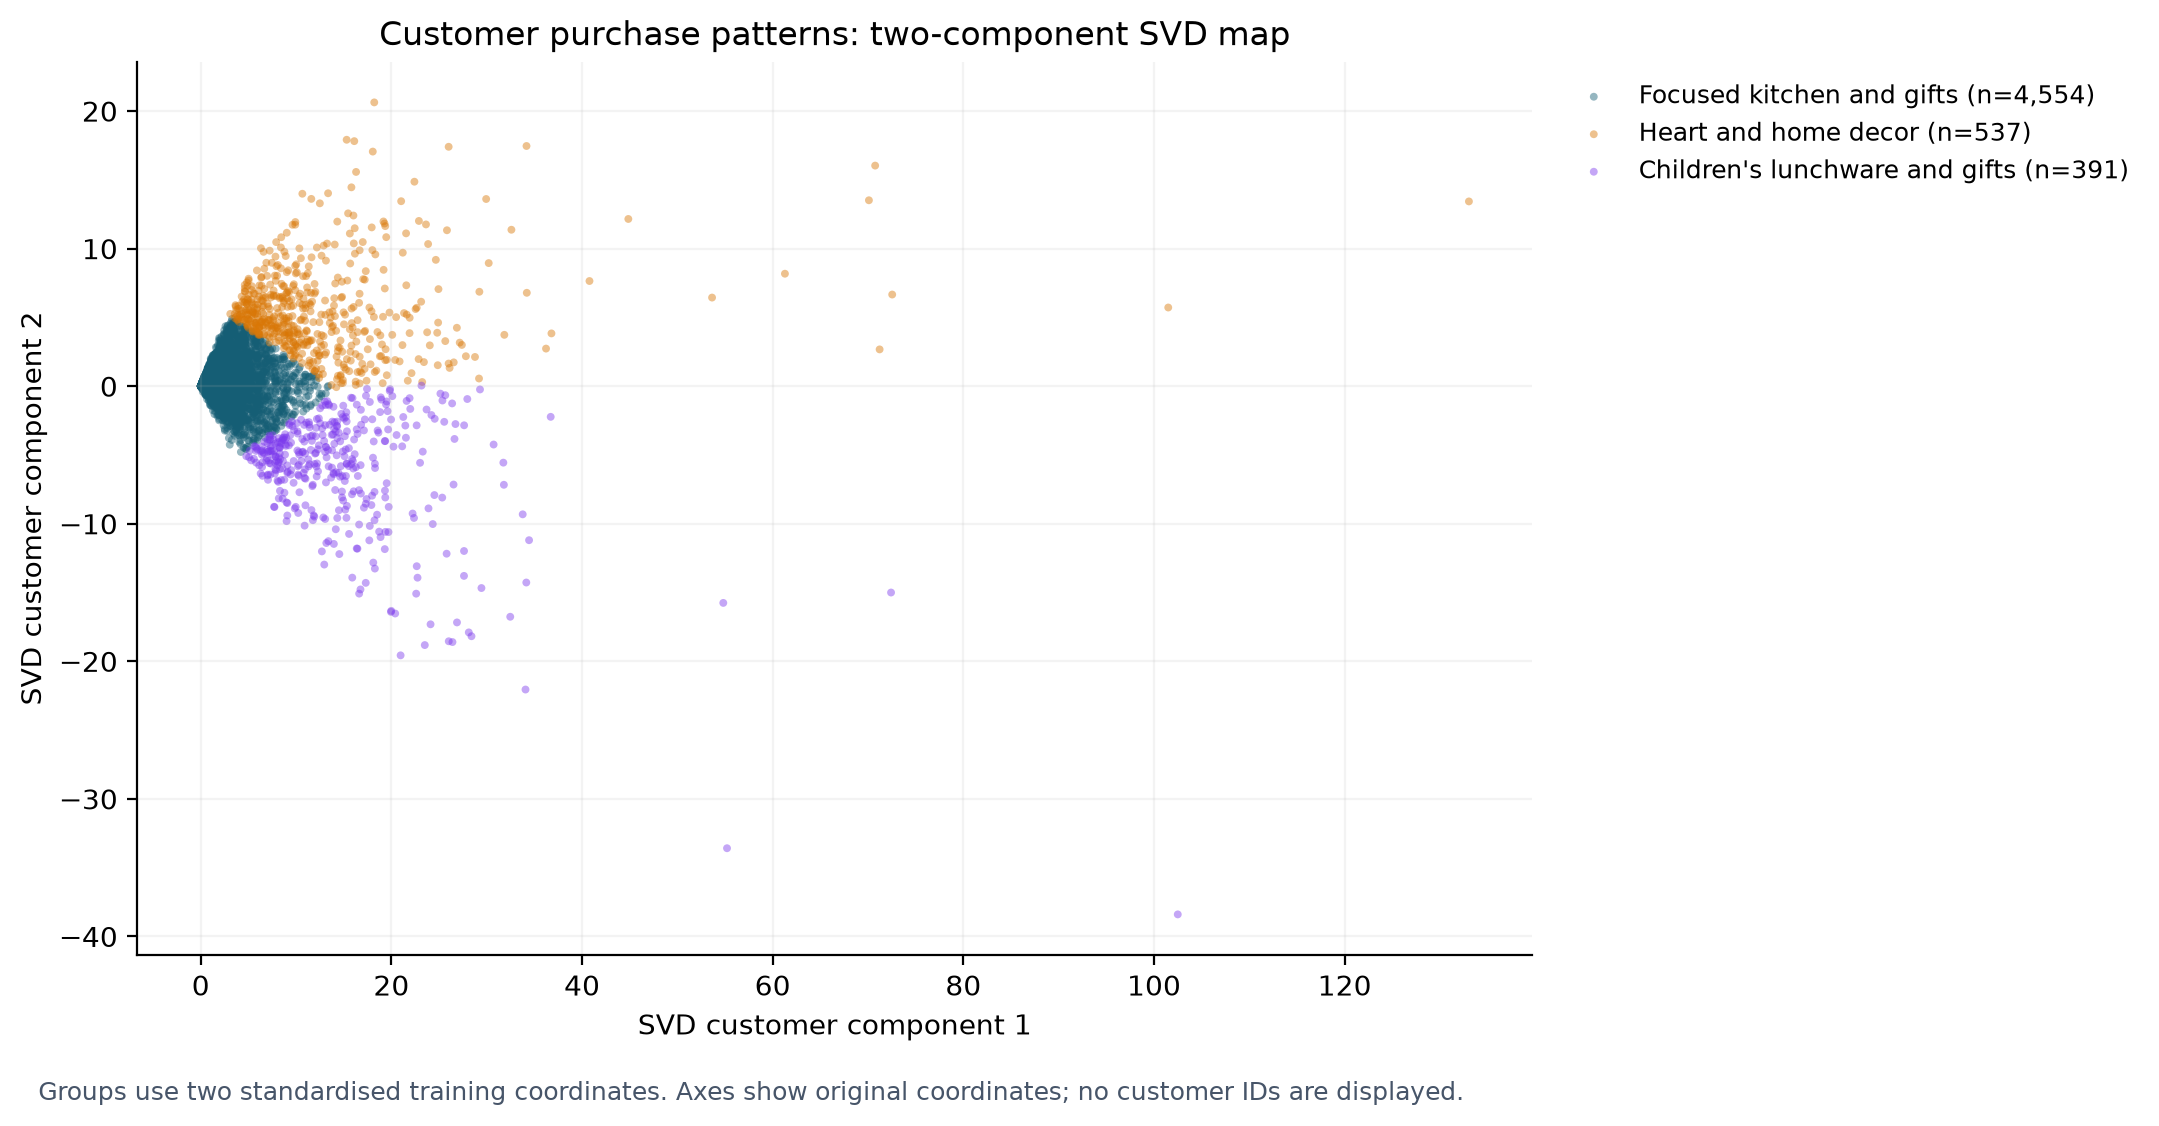

,groups,sampled_silhouette,selected
0,3,0.6340,True
1,4,0.6096,False
2,5,0.5764,False
3,6,0.5124,False


,group,segment_name,customers,customer_share_percent,median_distinct_products,median_log_weighted_volume,distinctive_products,popular_products,top_countries
0,0,Focused kitchen and gifts,4554,83.071872,32.0,65.223362,REX CASH+CARRY JUMBO SHOPPER; BAKING SET 9 PIECE RETROSPOT; REGENCY CAKESTAND 3 TIER; ...,WHITE HANGING HEART T-LIGHT HOLDER; REGENCY CAKESTAND 3 TIER; BAKING SET 9 PIECE RETRO...,United Kingdom 92.3%; France 1.3%; Germany 1.3%
1,1,Heart and home decor,537,9.795695,182.0,391.768664,T-LIGHT HOLDER SWEETHEART HANGING; HOUSE WRECKING METAL SIGN; FRENCH GARDEN SIGN BLUE ...,WHITE HANGING HEART T-LIGHT HOLDER; HEART OF WICKER SMALL; HEART OF WICKER LARGE; REGE...,United Kingdom 97.8%; EIRE 0.6%; Cyprus 0.4%
2,2,Children's lunchware and gifts,391,7.132433,171.0,449.136181,SPACEBOY BEAKER; SPACEBOY MINI BACKPACK; DOLLY GIRL BEAKER; CHARLOTTE BAG APPLES DESIG...,PACK OF 72 RETROSPOT CAKE CASES; LUNCH BAG RED RETROSPOT; LUNCH BAG SPACEBOY DESIGN; J...,United Kingdom 71.1%; Germany 9.5%; France 5.9%


In [8]:
map_coordinates = svd_scores[:,:2]
clustering_coordinates = StandardScaler().fit_transform(map_coordinates)
cluster_candidates, cluster_models = [], {}
for groups in range(3,7):
    km = KMeans(n_clusters=groups,random_state=SEED,n_init=20).fit(clustering_coordinates)
    silhouette = float(silhouette_score(clustering_coordinates,km.labels_,sample_size=min(2000,A.shape[0]),random_state=SEED))
    cluster_models[groups] = km
    cluster_candidates.append({'groups':groups,'sampled_silhouette':silhouette})
cluster_results = pd.DataFrame(cluster_candidates)
GROUPS = int(cluster_results.sort_values(['sampled_silhouette','groups'],ascending=[False,True]).iloc[0].groups)
cluster_results['selected'] = cluster_results.groups.eq(GROUPS)
cluster_results.to_csv(REPORTS/'cluster_selection.csv',index=False)
labels = cluster_models[GROUPS].labels_
binary = A.copy(); binary.data[:] = 1
global_prevalence = np.asarray(binary.mean(axis=0)).ravel()
country_counts = train.groupby(['Customer ID','Country']).size().rename('lines').reset_index()
customer_countries = country_counts.sort_values(['Customer ID','lines','Country'],ascending=[True,False,True]).drop_duplicates('Customer ID').set_index('Customer ID').Country.reindex(customers).fillna('Unknown').to_numpy()
segment_rows, segment_product_rows = [], []
segment_names = {}
for group in range(GROUPS):
    selected_rows = np.flatnonzero(labels==group)
    local_support = np.asarray(binary[selected_rows].sum(axis=0)).ravel()
    local_prevalence = local_support/len(selected_rows)
    lift = local_prevalence/np.maximum(global_prevalence,1e-12)
    supported = (local_support>=min(8,len(selected_rows)))&(local_prevalence>=.10)
    if supported.sum()<5:
        supported = local_support>=min(3,len(selected_rows))
    distinctive_order = np.argsort(-np.where(supported,lift,-np.inf),kind='stable')[:5]
    popular_order = np.argsort(-local_prevalence,kind='stable')[:5]
    top_countries = pd.Series(customer_countries[selected_rows]).value_counts(normalize=True).head(3)
    # Names are based on the actual leading distinctive products; explicit overrides may be added after inspecting training profiles.
    distinct_words = ' '.join(product_names[distinctive_order[:3]])
    if 'BAG' in distinct_words or 'LUNCH' in distinct_words:
        theme = 'Bags and lunchware'
    elif any(w in distinct_words for w in ['CHRISTMAS','XMAS','EASTER']):
        theme = 'Seasonal decorations'
    elif any(w in distinct_words for w in ['CAKE','JAM','BISCUIT','KITCHEN','TEA']):
        theme = 'Kitchen and tea gifts'
    elif any(w in distinct_words for w in ['HEART','CANDLE','T-LIGHT','TLIGHT']):
        theme = 'Heart and home gifts'
    else:
        theme = 'Home gift assortment'
    # Product-profile labels reviewed after the first training-only segment summary.
    reviewed_names = {0:'Focused kitchen and gifts', 1:'Heart and home decor', 2:'Children\'s lunchware and gifts'}
    theme = reviewed_names.get(group, theme)
    segment_names[group] = theme
    segment_rows.append({'group':group,'segment_name':theme,'customers':len(selected_rows),
        'customer_share_percent':100*len(selected_rows)/A.shape[0],
        'median_distinct_products':float(np.median(np.diff(A.indptr)[selected_rows])),
        'median_log_weighted_volume':float(np.median(volumes[selected_rows])),
        'distinctive_products':'; '.join(product_names[distinctive_order]),
        'popular_products':'; '.join(product_names[popular_order]),
        'top_countries':'; '.join(f'{c} {100*p:.1f}%' for c,p in top_countries.items())})
    for j in distinctive_order:
        segment_product_rows.append({'group':group,'segment_name':theme,'stock_code':products[j],
            'description':product_names[j],'group_prevalence_percent':100*local_prevalence[j],
            'global_prevalence_percent':100*global_prevalence[j],'prevalence_lift':lift[j]})
# Disambiguate repeated themes with measured purchasing breadth.
for theme in set(segment_names.values()):
    matches = [r for r in segment_rows if r['segment_name']==theme]
    if len(matches)>1:
        for number,r in enumerate(sorted(matches,key=lambda r:r['median_distinct_products'])):
            qualifier = ['Focused','Regular','Broad','Very broad'][min(number,3)]
            r['segment_name'] = f'{qualifier} {theme.lower()}'
            segment_names[r['group']] = r['segment_name']
for r in segment_product_rows:
    r['segment_name'] = segment_names[r['group']]
segments = pd.DataFrame(segment_rows)
segments.to_csv(REPORTS/'segments.csv',index=False)
pd.DataFrame(segment_product_rows).to_csv(REPORTS/'segment_products.csv',index=False)
np.savez(DATA/'customer_segments.npz',anonymous_row=np.arange(A.shape[0]),coordinates=map_coordinates,group=labels)
record_decision(17, f'Map: standardise the first two training SVD coordinates for k-means, giving each axis equal weight; select {GROUPS} groups by the largest sampled silhouette among 3-6. Plot original coordinates and name groups from product prevalence lift.')
fig, ax = plt.subplots(figsize=(9,5.8))
colors = ['#155E75','#D97706','#7C3AED','#15803D','#BE185D','#475569']
for group in range(GROUPS):
    mask = labels==group
    ax.scatter(map_coordinates[mask,0],map_coordinates[mask,1],s=8,alpha=.45,c=colors[group],edgecolors='none',label=f"{segment_names[group]} (n={mask.sum():,})")
ax.set(xlabel='SVD customer component 1',ylabel='SVD customer component 2',title='Customer purchase patterns: two-component SVD map')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),frameon=False,fontsize=9)
ax.grid(alpha=.15)
fig.text(.07,-.015,'Groups use two standardised training coordinates. Axes show original coordinates; no customer IDs are displayed.',fontsize=9,color='#475569')
show_figure(fig,'customer_map.png')
display(cluster_results.round(4))
display(segments)

## Results and reproducibility checks

The following assertions verify temporal isolation, matrix consistency, recommendation exclusions and the shared comparison cohort. Runtime varies across executions; model outputs are deterministic for the fixed environment and seed. See README for the command and artifact inventory.

In [9]:
svd_eval = evaluation.set_index('method').loc['SVD']
pca_eval = evaluation.set_index('method').loc['PCA']
svd_timing = timings.set_index('method').loc['SVD']
factor_mb = svd_stats['factor_bytes']/1e6
dense_reduction = 100*(1-svd_stats['factor_bytes']/dense_bytes)
sparse_change = 100*(1-svd_stats['factor_bytes']/csr_bytes)
history_bytes = A.data.nbytes+A.indices.nbytes+A.indptr.nbytes
recommendation_cache_bytes = model_recommendations['SVD'].nbytes + len(products)*10*(np.dtype('int32').itemsize+np.dtype('float64').itemsize)
summary = {'raw_rows':raw_stats['rows'],'clean_rows':len(clean),'training_rows':len(train),'test_rows':len(test_period),
    'customers':A.shape[0],'products':A.shape[1],'chosen_k':CHOSEN_K,
    'relative_reconstruction_error':svd_stats['relative_reconstruction_error'],
    'dense_mb':dense_bytes/1e6,'csr_mb':csr_bytes/1e6,'factor_mb':factor_mb,
    'dense_reduction_percent':dense_reduction,'csr_reduction_percent':sparse_change,
    'history_plus_factors_and_top10_cache_mb':(history_bytes+svd_stats['factor_bytes']+recommendation_cache_bytes)/1e6,
    'svd_hit_rate':float(svd_eval.hit_rate_at_10),'pca_hit_rate':float(pca_eval.hit_rate_at_10),
    'baseline_hit_rate':baseline_rate,'svd_hit_customers':int(svd_eval.hit_customers),
    'baseline_hit_customers':int(baseline_hits.sum()),'eligible_customers':len(test_targets),
    'svd_baseline_difference_pp':float(svd_eval.difference_percentage_points),
    'svd_baseline_difference_ci_pp':ci.tolist(),
    'fit_seconds':float(svd_timing.fit_seconds),'catalogue_refresh_seconds':float(svd_timing.catalogue_refresh_seconds),
    'customer_scoring_seconds':float(svd_timing.all_customer_scoring_seconds),
    'fit_plus_catalogue_seconds':float(svd_timing.fit_plus_catalogue_seconds),
    'model_refresh_total_seconds':float(svd_timing.model_refresh_total_seconds),
    'groups':GROUPS,'novel_pair_coverage_percent':split_summary['novel_pair_coverage_percent'],
    'test_start':test_start.strftime('%Y-%m-%d'),'test_end_exclusive':test_end.strftime('%Y-%m-%d'),
    'target_dense_compression_met':bool(dense_reduction>=90),
    'target_fit_plus_catalogue_under_60s_met':bool(svd_timing.fit_plus_catalogue_seconds<60),
    'target_beats_baseline_met':bool(svd_eval.hit_rate_at_10>baseline_rate),
    'target_groups_met':bool(3<=GROUPS<=6)}
summary['pipeline_seconds_before_memo'] = time.perf_counter()-pipeline_start
write_json(REPORTS/'results_summary.json',summary)
environment['raw_load_seconds'] = raw_stats['load_seconds']
environment['threadpools'] = threadpool_info()
write_json(REPORTS/'environment.json',environment)
checks = {'two_sheets_loaded':len(sheet_rows)==2, 'cleaning_counts_reconcile':bool(cleaning_log.rows_removed.sum()+len(clean)==raw_stats['rows']),
    'training_precedes_test':bool(train.InvoiceDate.max()<test_period.InvoiceDate.min()),
    'test_targets_absent_from_full_training_history':not pd.MultiIndex.from_frame(novel[pair_cols]).isin(train_pair_index).any(),
    'positive_finite_sparse_values':bool(np.all(A.data>0)&np.isfinite(A.data).all()),
    'no_test_target_in_matrix':all(A[r,list(t)].nnz==0 for r,t in test_targets.items()),
    'same_model_k':svd_stats['k']==pca_stats['k']==CHOSEN_K,
    'same_model_test_denominator':bool(evaluation.eligible_customers.nunique()==1),
    'recommendations_distinct_and_unseen':all(len(set(model_recommendations[m][r]))==10 and
        not np.intersect1d(A.indices[A.indptr[r]:A.indptr[r+1]],model_recommendations[m][r]).size
        for m in ['SVD','PCA'] for r in range(A.shape[0])),
    'baseline_distinct_and_unseen':all(len(set(baseline_recommendations[r]))==10 and
        not np.intersect1d(A.indices[A.indptr[r]:A.indptr[r+1]],baseline_recommendations[r]).size for r in range(A.shape[0])),
    'svd_projection_identity_check':all(s['small_dense_error_check'] for s in rank_stats),
    'pca_projection_identity_check':pca_stats['small_dense_error_check'],
    'segment_membership_complete':bool(segments.customers.sum()==A.shape[0]),
    'selected_k_frozen_before_evaluation':not json.loads((DATA/'frozen_model_choice.json').read_text())['test_results_read_for_choice']}
assert all(checks.values()), checks
write_json(REPORTS/'verification.json',checks)
record_decision(18, 'Final test results are reported as observed; no rank, filter, weighting or scoring change follows test evaluation. Compression does not establish recommendation quality.')
display(pd.DataFrame({'check':list(checks),'passed':list(checks.values())}))
print(f"SVD: {100*summary['svd_hit_rate']:.2f}% | PCA: {100*summary['pca_hit_rate']:.2f}% | best sellers: {100*baseline_rate:.2f}%")

,check,passed
0,two_sheets_loaded,True
1,cleaning_counts_reconcile,True
2,training_precedes_test,True
3,test_targets_absent_from_full_training_history,True
4,positive_finite_sparse_values,True
5,no_test_target_in_matrix,True
6,same_model_k,True
7,same_model_test_denominator,True
8,recommendations_distinct_and_unseen,True
9,baseline_distinct_and_unseen,True


SVD: 21.26% | PCA: 21.52% | best sellers: 17.38%


## J2: one-page memo

The memo below is generated from the same measured results. It gives Sarah a decision, the method, compression loss, size and speed, customer groups, risks and next steps.

In [10]:
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_LEFT
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, KeepTogether
from xml.sax.saxutils import escape
from pypdf import PdfReader

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name='MemoTitle',fontName='Helvetica-Bold',fontSize=20,leading=24,textColor=colors.HexColor('#17324D'),spaceAfter=6))
styles.add(ParagraphStyle(name='MemoBody',fontName='Helvetica',fontSize=10.1,leading=13.6,spaceAfter=7,textColor=colors.HexColor('#182A3A')))
styles.add(ParagraphStyle(name='MemoHead',fontName='Helvetica-Bold',fontSize=11,leading=14,spaceBefore=5,spaceAfter=4,textColor=colors.HexColor('#17324D')))
styles.add(ParagraphStyle(name='MemoSmall',fontName='Helvetica',fontSize=8,leading=10.5,textColor=colors.HexColor('#526375')))
def para(text, style='MemoBody'):
    return Paragraph(text,styles[style])
beat = summary['svd_hit_rate']>baseline_rate
verdict = ('Use SVD as a candidate for a small recommendation trial.' if beat else
           'Keep best sellers as the production default; SVD needs improvement before a trial.')
memo_story = [para('Customers Like You','MemoTitle'),
              para('To: Sarah Okafor, Head of E-Commerce &nbsp;&nbsp; From: Data &amp; ML &nbsp;&nbsp; 13 October 2026','MemoSmall'),
              Spacer(1,10),para(verdict,'MemoHead')]
memo_story.append(para(f"On {summary['eligible_customers']:,} returning customers with eligible new purchases, SVD placed at least one actual new purchase in the top 10 for <b>{100*summary['svd_hit_rate']:.1f}%</b>, compared with <b>{100*baseline_rate:.1f}%</b> for unseen best sellers. The difference is {summary['svd_baseline_difference_pp']:+.1f} percentage points. PCA reached {100*summary['pca_hit_rate']:.1f}% on the same customers."))
memo_story.append(para('Method and what compression loses','MemoHead'))
memo_story.append(para(f"We used Truncated SVD with {CHOSEN_K} components. It retains the largest singular values to preserve strong shared purchase patterns, and works directly on the sparse purchase table. Products are suggested through similarity to items a customer bought. PCA, our required comparison, describes departures from the average customer. Keeping fewer patterns loses detail, especially for uncommon products. Relative table reconstruction error is {100*summary['relative_reconstruction_error']:.1f}%; recommendation hit rate measures purchase matching separately."))
memo_story.append(para('Size and nightly speed','MemoHead'))
memo_story.append(para(f"Factors occupy <b>{factor_mb:.2f} MB</b>, versus {dense_bytes/1e6:.2f} MB for the full dense table ({dense_reduction:.1f}% smaller) and {csr_bytes/1e6:.2f} MB for sparse storage. Keeping purchase history and top-10 caches brings the array total to {summary['history_plus_factors_and_top10_cache_mb']:.2f} MB, excluding labels and file overhead. Fitting plus product-page refresh took {summary['fit_plus_catalogue_seconds']:.2f} seconds; scoring all customers took another {summary['customer_scoring_seconds']:.2f} seconds. These are local, single-thread timings; raw Excel loading is separate."))
memo_story.append(para('Customer groups for marketing','MemoHead'))
group_sentence = '; '.join(f"{escape(r.segment_name)} ({r.customers:,})" for r in segments.itertuples())
memo_story.append(para(f"The two-component map contains {GROUPS} exploratory groups: {group_sentence}. Names reflect characteristic products. Country mixes are reported separately; groups also differ in purchase breadth. The map is a simplified view and needs campaign testing."))
memo_story.append(para('Risks and next steps','MemoHead'))
memo_story.append(para(f"Test dates were {test_start:%d %b} to {(test_end-pd.Timedelta(days=1)):%d %b %Y}. Evaluation covers {summary['novel_pair_coverage_percent']:.1f}% of all new test purchase pairs after customer and catalogue exclusions. New customers and unseen products need a best-seller fallback. Popularity, wholesale volume and seasonal demand may influence results. Returns were excluded; missing purchases do not express dislikes. {'Validate on a later period, review suggestions and run a controlled trial.' if beat else 'Review ranking and popularity effects using an earlier validation period, then test on new untouched data.'} Keep customer identifiers private."))
memo_story.extend([Spacer(1,5),para('Source: Chen (2012), Online Retail II, UCI. doi:10.24432/C5CG6D. CC BY 4.0. Full evidence and reproducible analysis accompany this memo.','MemoSmall')])

def memo_footer(canvas,doc):
    canvas.setStrokeColor(colors.HexColor('#C8D5DF'));canvas.setLineWidth(.6)
    canvas.line(46,34,566,34)
    canvas.setFont('Helvetica',8);canvas.setFillColor(colors.HexColor('#526375'))
    canvas.drawString(46,22,'GiftLane | Individual mini-project | SVD recommendation analysis')
    canvas.drawRightString(566,22,str(doc.page))
memo = SimpleDocTemplate(str(ROOT/'memo.pdf'),pagesize=letter,leftMargin=46,rightMargin=46,topMargin=36,bottomMargin=43,
                         title='Customers Like You: recommendation decision',author='Data and ML analysis')
memo.build(memo_story,onFirstPage=memo_footer,onLaterPages=memo_footer)
assert len(PdfReader(ROOT/'memo.pdf').pages)==1, 'Memo must be exactly one page; revise layout.'
print('Generated memo.pdf: one page.')

Generated memo.pdf: one page.
